# 03 — Stratégie ETF Momentum défensive PEA (Projet 2)

Notebook de recherche **éducatif**. Il enchaîne : configuration → données → features (momentum 12-1, moyenne mobile) → signaux (éligibilité, classement, poids, décalage) → backtests mensuels avec frais → robustesse → graphiques → contrôles.

> **Avertissement.** Ceci n'est pas un conseil d'investissement. Aucun ordre n'est exécuté. La décision reste manuelle. Données Yahoo Finance via yfinance (source non officielle, à revérifier chez un courtier avant tout usage réel).

## 1. Initialisation

Détection de la racine du projet, ajout au `sys.path`, contrôle des dépendances.

In [1]:
import sys
from pathlib import Path


def find_project_root(markers=("src", "config")) -> Path:
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if all((candidate / m).is_dir() for m in markers):
            return candidate
    raise RuntimeError("Racine du projet introuvable.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

for folder in ["src", "data", "config", "tests"]:
    assert (PROJECT_ROOT / folder).is_dir(), f"Dossier manquant : {folder}"

print("Racine :", PROJECT_ROOT)

Racine : C:\Users\degar\OneDrive - De Vinci Higher Education (DVHE)\Perso\Projet Investissement\personal-quant-lab


## 2. Imports

In [2]:
%matplotlib inline
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import download_prices, load_prices, save_prices, load_tickers_from_yaml, validate_prices
from src.features import to_monthly_prices, compute_momentum, compute_moving_average, compute_trend_filter
from src.signals import build_momentum_weights, compute_eligibility, rank_by_momentum, select_top_n_weights, lag_weights_for_execution, CASH_COLUMN
from src.backtest import backtest_monthly_allocation, buy_and_hold
from src.metrics import performance_summary, compute_drawdown, yearly_returns

for dep in ("pandas", "numpy", "matplotlib", "yfinance"):
    assert importlib.util.find_spec(dep) is not None, f"Dépendance manquante : {dep}"
print("Imports OK")

Imports OK


## 3. Chargement des données

On lit l'univers depuis `config/assets.yaml` et on ne garde que les **ETF** (tickers `.PA`) : les cryptos sont volontairement exclues de ce projet. Téléchargement contrôlé avec repli sur le fichier local en cas de coupure réseau.

In [3]:
BENCHMARK = "CW8.PA"
START = "2015-01-01"
UNIVERSE_CSV = PROJECT_ROOT / "data" / "processed" / "momentum_universe.csv"

all_tickers = load_tickers_from_yaml(PROJECT_ROOT / "config" / "assets.yaml")
etf_tickers = [t for t in all_tickers if t.endswith(".PA")]
print("Tickers ETF candidats :", etf_tickers)
print("Exclus de ce projet (crypto) :", [t for t in all_tickers if t not in etf_tickers])

prices = None
try:
    prices = download_prices(etf_tickers, start=START)
    prices = validate_prices(prices)
    save_prices(prices, UNIVERSE_CSV)
    print("Téléchargement OK, sauvegardé ->", UNIVERSE_CSV.relative_to(PROJECT_ROOT))
except Exception as exc:
    print("Réseau indisponible :", exc)
    if UNIVERSE_CSV.exists():
        prices = load_prices(UNIVERSE_CSV)
        print("Repli sur le fichier local.")
    else:
        raise RuntimeError("Aucune donnée (réseau KO et pas de fichier local).")

prices.tail()

Tickers ETF candidats : ['CW8.PA', 'EWLD.PA', 'ESE.PA']
Exclus de ce projet (crypto) : ['BTC-USD', 'ETH-USD']


Téléchargement OK, sauvegardé -> data\processed\momentum_universe.csv


,CW8.PA,EWLD.PA,ESE.PA
Date,,,
2026-07-02,681.979980,40.404999,33.133900
2026-07-03,684.520020,40.564999,33.215599
2026-07-06,687.739990,40.744999,33.416500
2026-07-07,682.530029,40.435001,33.171600
2026-07-08,677.539978,40.160000,33.021500


## 4. Exploration et sélection de l'univers

On mesure la couverture par actif. Un momentum 12-1 combiné à une moyenne mobile 10 mois exige au moins ~22 mois d'historique ; on retient donc les ETF disposant d'assez de mois valides et on **documente les exclusions**.

In [4]:
LOOKBACK, SKIP, MA_WINDOW = 12, 1, 10
MIN_HISTORY_MONTHS = LOOKBACK + MA_WINDOW + 12  # marge de sécurité

monthly_all = to_monthly_prices(prices)

coverage = pd.DataFrame({
    "premier": prices.apply(lambda s: s.dropna().index.min().date()),
    "dernier": prices.apply(lambda s: s.dropna().index.max().date()),
    "obs_quotidiennes": prices.notna().sum(),
    "obs_mensuelles": monthly_all.notna().sum(),
    "NaN_quotidiens": prices.isna().sum(),
})
print(coverage)

kept = [c for c in prices.columns if monthly_all[c].notna().sum() >= MIN_HISTORY_MONTHS]
excluded = [c for c in prices.columns if c not in kept]
print("\nUnivers retenu :", kept)
print("Exclus (historique insuffisant) :", excluded)
assert BENCHMARK in kept, "Le benchmark doit faire partie de l'univers retenu."

universe_prices = prices[kept].copy()
monthly_prices = to_monthly_prices(universe_prices)
common = universe_prices.dropna(how="any")
print("\nPériode commune (tous retenus valides) :", common.index.min().date(), "->", common.index.max().date())
print("Prix mensuels — dernières lignes :")
monthly_prices.tail(3)

            premier     dernier  obs_quotidiennes  obs_mensuelles  \
CW8.PA   2015-01-02  2026-07-08              2947             139   
EWLD.PA  2024-03-15  2026-07-08               589              29   
ESE.PA   2015-01-02  2026-07-08              2945             139   

         NaN_quotidiens  
CW8.PA                0  
EWLD.PA            2358  
ESE.PA                2  

Univers retenu : ['CW8.PA', 'ESE.PA']
Exclus (historique insuffisant) : ['EWLD.PA']

Période commune (tous retenus valides) : 2015-01-02 -> 2026-07-08
Prix mensuels — dernières lignes :


,CW8.PA,ESE.PA
Date,,
2026-05-31,671.998230,32.864399
2026-06-30,681.229980,33.161900
2026-07-31,677.539978,33.021500


## 5. Features

Momentum **12-1** (`prix(t-1)/prix(t-12)-1`), moyenne mobile **10 mois**, et filtre de tendance `prix > MA`. Rappel : aucune donnée future, les `NaN` de démarrage sont normaux et conservés.

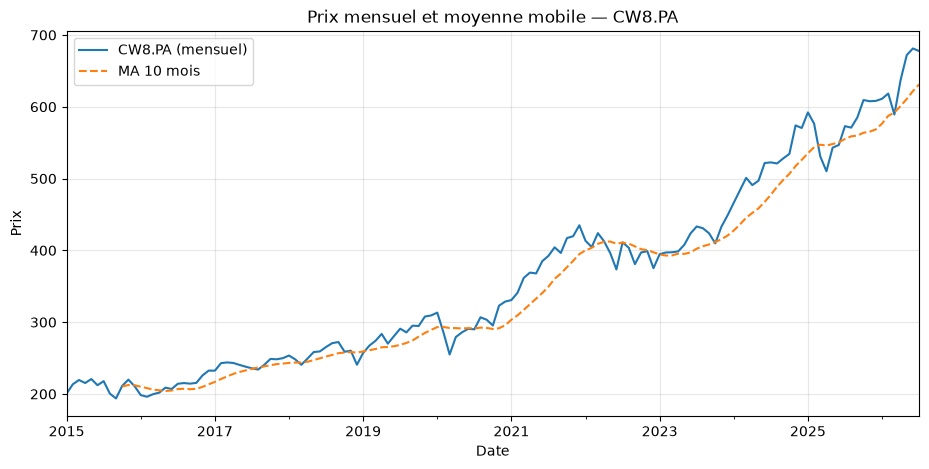

Signaux récents (momentum / prix>MA) :


momentum           prix>MA       
              CW8.PA    ESE.PA  CW8.PA ESE.PA
Date                                         
2026-02-28  0.059911  0.038253       1      1
2026-03-31  0.165037  0.139514       0      0
2026-04-30  0.154961  0.156267       1      1
2026-05-31  0.173338  0.185196       1      1
2026-06-30  0.229036  0.241994       1      1
2026-07-31  0.188809  0.180975       1      1

In [5]:
momentum = compute_momentum(monthly_prices, LOOKBACK, SKIP)
ma = compute_moving_average(monthly_prices, MA_WINDOW)
trend = compute_trend_filter(monthly_prices, ma)

fig, ax = plt.subplots(figsize=(11, 5))
monthly_prices[BENCHMARK].plot(ax=ax, label=f"{BENCHMARK} (mensuel)")
ma[BENCHMARK].plot(ax=ax, label=f"MA {MA_WINDOW} mois", linestyle="--")
ax.set_title(f"Prix mensuel et moyenne mobile — {BENCHMARK}")
ax.set_ylabel("Prix"); ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

print("Signaux récents (momentum / prix>MA) :")
recent = pd.concat({"momentum": momentum, "prix>MA": trend.astype(int)}, axis=1).tail(6)
recent

## 6. Signaux

Éligibilité (momentum disponible **et** tendance positive), classement par momentum, poids cibles, puis **décalage d'un mois** pour l'exécution. Les premières périodes et les périodes sans actif éligible sont en cash.

In [6]:
eligible = compute_eligibility(momentum, trend)
ranks = rank_by_momentum(momentum, eligible)
target_weights = select_top_n_weights(momentum, eligible, top_n=1)
executed_weights = lag_weights_for_execution(target_weights, periods=1)

print("Poids cibles (fin de mois) — 6 dernières lignes :")
print(target_weights.tail(6).round(3))
print("\nPoids exécutés (décalés d'un mois) — 6 dernières lignes :")
print(executed_weights.tail(6).round(3))

n_cash = int((executed_weights[CASH_COLUMN] > 0.999).sum())
print(f"\nMois 100% cash : {n_cash} / {len(executed_weights)}")

Poids cibles (fin de mois) — 6 dernières lignes :
            CW8.PA  ESE.PA  CASH
Date                            
2026-02-28     1.0     0.0   0.0
2026-03-31     0.0     0.0   1.0
2026-04-30     0.0     1.0   0.0
2026-05-31     0.0     1.0   0.0
2026-06-30     0.0     1.0   0.0
2026-07-31     1.0     0.0   0.0

Poids exécutés (décalés d'un mois) — 6 dernières lignes :
            CW8.PA  ESE.PA  CASH
Date                            
2026-02-28     1.0     0.0   0.0
2026-03-31     1.0     0.0   0.0
2026-04-30     0.0     0.0   1.0
2026-05-31     0.0     1.0   0.0
2026-06-30     0.0     1.0   0.0
2026-07-31     0.0     1.0   0.0

Mois 100% cash : 33 / 139


## 7. Backtests comparés

On compare le Buy & Hold du benchmark à plusieurs variantes momentum, **frais inclus** (0,10 %). On n'optimise pas le rendement : on regarde le couple rendement/risque, le drawdown, le turnover et le temps passé en cash.

In [7]:
INITIAL_CAPITAL = 10_000.0
DEFAULT_TC = 0.001
PPY = 12  # périodes par an (mensuel)


def run_config(daily_prices, lookback, skip, ma_window, top_n, tc, use_trend=True):
    res = build_momentum_weights(daily_prices, lookback, skip, ma_window, top_n, use_trend_filter=use_trend)
    bt = backtest_monthly_allocation(res["monthly_prices"], res["executed_weights"],
                                     initial_capital=INITIAL_CAPITAL, transaction_cost=tc)
    summ = performance_summary(bt["Net Return"].dropna(), bt["Equity Curve"], periods_per_year=PPY)
    return res, bt


# Benchmark Buy & Hold sur les prix mensuels du benchmark.
monthly_bench = to_monthly_prices(universe_prices[BENCHMARK]).dropna()
bench = buy_and_hold(monthly_bench, initial_capital=INITIAL_CAPITAL)
bench_summary = performance_summary(bench["Returns"].dropna(), bench["Equity Curve"], periods_per_year=PPY)

strategies = {}
_, strategies["Mom 12-1 (sans tendance)"] = run_config(universe_prices, 12, 1, MA_WINDOW, 1, DEFAULT_TC, use_trend=False)
main_res, strategies["Mom 12-1 + MA10"] = run_config(universe_prices, 12, 1, 10, 1, DEFAULT_TC)
_, strategies["Mom 6-1 + MA10"] = run_config(universe_prices, 6, 1, 10, 1, DEFAULT_TC)
if len(kept) >= 2:
    _, strategies["Mom 12-1 + MA10 (top2)"] = run_config(universe_prices, 12, 1, 10, 2, DEFAULT_TC)

rows = {"Buy & Hold " + BENCHMARK: bench_summary}
for name, bt in strategies.items():
    rows[name] = performance_summary(bt["Net Return"].dropna(), bt["Equity Curve"], periods_per_year=PPY)

comparison = pd.DataFrame(rows).T
comparison["Months in cash"] = [0] + [int((bt["Cash Weight"] > 0.999).sum()) for bt in strategies.values()]
comparison["Avg turnover"] = [0.0] + [bt["Turnover"].mean() for bt in strategies.values()]
comparison.round(4)

,CAGR,Volatility,Sharpe,Max Drawdown,Best Year,Worst Year,Final Capital,Months in cash,Avg turnover
Buy & Hold CW8.PA,0.1117,0.1323,0.8699,-0.1861,0.3234,-0.1374,33804.1845,0,0.0000
Mom 12-1 (sans tendance),0.1309,0.1324,0.9990,-0.1764,0.4126,-0.1410,41568.2676,13,0.1079
Mom 12-1 + MA10,0.0872,0.1090,0.8237,-0.1658,0.4126,-0.1658,26335.8171,33,0.2158
Mom 6-1 + MA10,0.0753,0.1121,0.7051,-0.1658,0.3816,-0.1658,23181.9443,30,0.2446
Mom 12-1 + MA10 (top2),0.0725,0.0995,0.7547,-0.1373,0.3632,-0.1373,22497.2947,33,0.1367


## 8. Robustesse (grille explicite)

Grille bornée : lookback ∈ {3,6,12}, skip ∈ {0,1}, MA ∈ {6,10,12}, top_n ∈ {1,2}, frais ∈ {0 ; 0,10 ; 0,20 ; 0,30 %}. On **ne sélectionne pas** le meilleur rendement : on observe la stabilité (Sharpe, drawdown, turnover, frais, mois en cash).

In [8]:
grid_rows = []
for lookback in (3, 6, 12):
    for skip in (0, 1):
        for ma_window in (6, 10, 12):
            for top_n in (1, 2):
                if top_n == 2 and len(kept) < 2:
                    continue
                for tc in (0.0, 0.001, 0.002, 0.003):
                    _, bt = run_config(universe_prices, lookback, skip, ma_window, top_n, tc)
                    s = performance_summary(bt["Net Return"].dropna(), bt["Equity Curve"], periods_per_year=PPY)
                    grid_rows.append({
                        "lookback": lookback, "skip": skip, "ma": ma_window, "top_n": top_n,
                        "frais_%": tc * 100,
                        "CAGR_%": s["CAGR"] * 100, "Vol_%": s["Volatility"] * 100,
                        "Sharpe": s["Sharpe"], "MaxDD_%": s["Max Drawdown"] * 100,
                        "Turnover": bt["Turnover"].mean(),
                        "Mois_cash": int((bt["Cash Weight"] > 0.999).sum()),
                        "Capital_final": s["Final Capital"],
                    })

grid = pd.DataFrame(grid_rows)
print("Combinaisons évaluées :", len(grid))
print("\nRésumé par (lookback, skip, ma, top_n) à frais 0,10 % :")
grid[grid["frais_%"] == 0.1].drop(columns="frais_%").round(3).reset_index(drop=True)

Combinaisons évaluées : 144

Résumé par (lookback, skip, ma, top_n) à frais 0,10 % :


,lookback,skip,ma,top_n,CAGR_%,Vol_%,Sharpe,MaxDD_%,Turnover,Mois_cash,Capital_final
0,3,0,6,1,5.761,10.572,0.584,-23.196,0.367,36,19131.808
1,3,0,6,2,6.540,10.199,0.673,-18.919,0.194,36,20829.001
2,3,0,10,1,7.009,10.848,0.680,-17.855,0.331,30,21916.341
3,3,0,10,2,6.945,10.162,0.713,-13.734,0.151,30,21766.081
4,3,0,12,1,8.704,10.997,0.816,-16.005,0.295,31,26292.576
5,3,0,12,2,8.662,10.435,0.851,-12.773,0.108,31,26175.734
6,3,1,6,1,5.060,10.407,0.527,-23.447,0.439,36,17714.927
7,3,1,6,2,6.540,10.199,0.673,-18.919,0.194,36,20829.001
8,3,1,10,1,6.300,10.694,0.626,-18.126,0.403,30,20292.933
9,3,1,10,2,6.945,10.162,0.713,-13.734,0.151,30,21766.081


In [9]:
# Sensibilité aux frais (moyenne sur toutes les configs) : les frais dégradent la performance.
fee_sensitivity = grid.groupby("frais_%")[["CAGR_%", "Capital_final"]].mean().round(3)
print("Sensibilité moyenne aux frais :")
print(fee_sensitivity)
assert fee_sensitivity["Capital_final"].is_monotonic_decreasing, "Plus de frais doit réduire le capital moyen."

Sensibilité moyenne aux frais :
         CAGR_%  Capital_final
frais_%                       
0.0       7.971      24496.495
0.1       7.703      23816.773
0.2       7.436      23158.360
0.3       7.169      22520.507


## 9. Graphiques

Stratégie principale : **Momentum 12-1 + MA 10 mois, top 1, frais 0,10 %**.

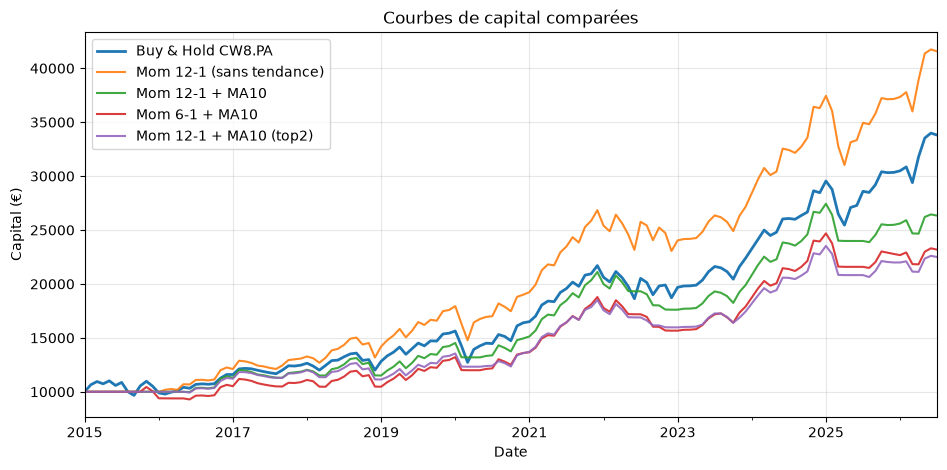

In [10]:
main_bt = strategies["Mom 12-1 + MA10"]
main_equity = main_bt["Equity Curve"]

# 1) Equity curves comparées
fig, ax = plt.subplots(figsize=(11, 5))
bench["Equity Curve"].plot(ax=ax, label="Buy & Hold " + BENCHMARK, linewidth=2)
for name, bt in strategies.items():
    bt["Equity Curve"].plot(ax=ax, label=name, alpha=0.9)
ax.set_title("Courbes de capital comparées"); ax.set_ylabel("Capital (€)")
ax.legend(); ax.grid(True, alpha=0.3); plt.show()

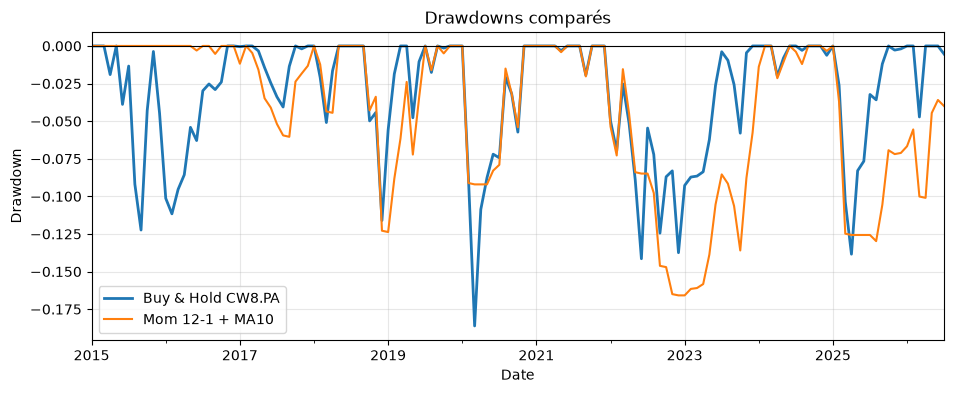

In [11]:
# 2) Drawdowns comparés
fig, ax = plt.subplots(figsize=(11, 4))
compute_drawdown(bench["Equity Curve"]).plot(ax=ax, label="Buy & Hold " + BENCHMARK, linewidth=2)
compute_drawdown(main_equity).plot(ax=ax, label="Mom 12-1 + MA10")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Drawdowns comparés"); ax.set_ylabel("Drawdown"); ax.legend(); ax.grid(True, alpha=0.3); plt.show()

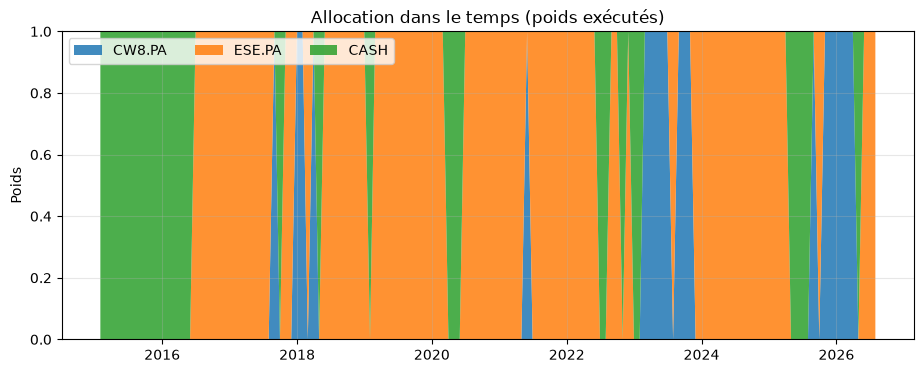

In [12]:
# 3) Allocation dans le temps (poids exécutés, stratégie principale)
ew = main_res["executed_weights"]
plot_cols = [c for c in ew.columns if c != CASH_COLUMN] + [CASH_COLUMN]
fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(ew.index, [ew[c] for c in plot_cols], labels=plot_cols, alpha=0.85)
ax.set_title("Allocation dans le temps (poids exécutés)"); ax.set_ylabel("Poids")
ax.set_ylim(0, 1); ax.legend(loc="upper left", ncol=len(plot_cols)); ax.grid(True, alpha=0.3); plt.show()

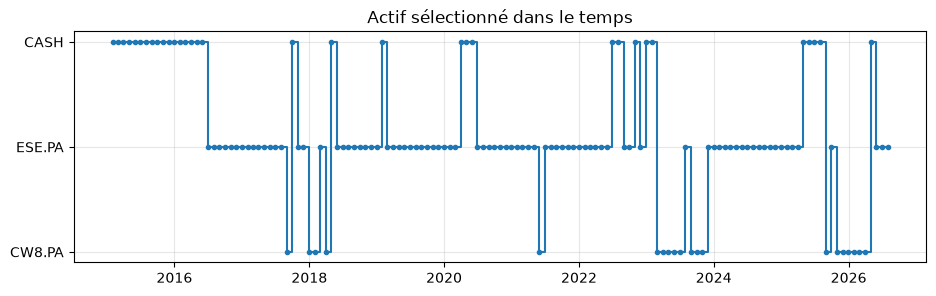

In [13]:
# 4) Actif sélectionné dans le temps
labels = list(main_res["executed_weights"].columns)
codes = main_bt["Selected Assets"].map(lambda s: labels.index(s.split(",")[0]) if s in labels else labels.index(CASH_COLUMN))
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(codes.index, codes.values, drawstyle="steps-post", marker=".")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_title("Actif sélectionné dans le temps"); ax.grid(True, alpha=0.3); plt.show()

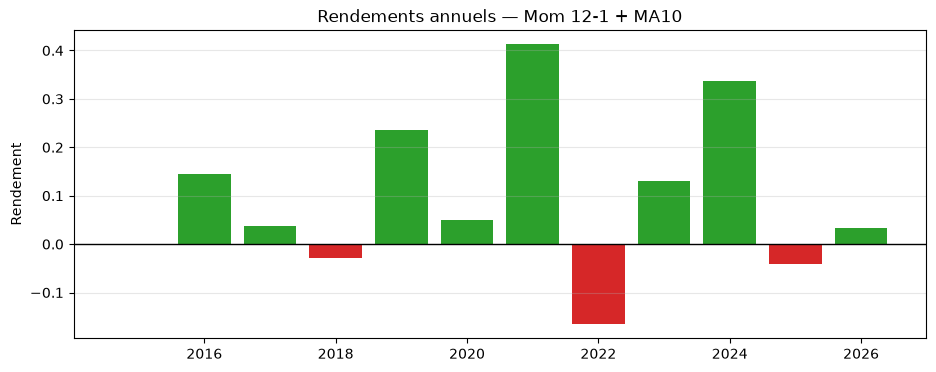

In [14]:
# 5) Rendements annuels (stratégie principale)
annual = yearly_returns(main_bt["Net Return"].dropna())
fig, ax = plt.subplots(figsize=(11, 4))
colors = ["#2ca02c" if v >= 0 else "#d62728" for v in annual.values]
ax.bar(annual.index.year, annual.values, color=colors)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Rendements annuels — Mom 12-1 + MA10"); ax.set_ylabel("Rendement")
ax.grid(True, axis="y", alpha=0.3); plt.show()

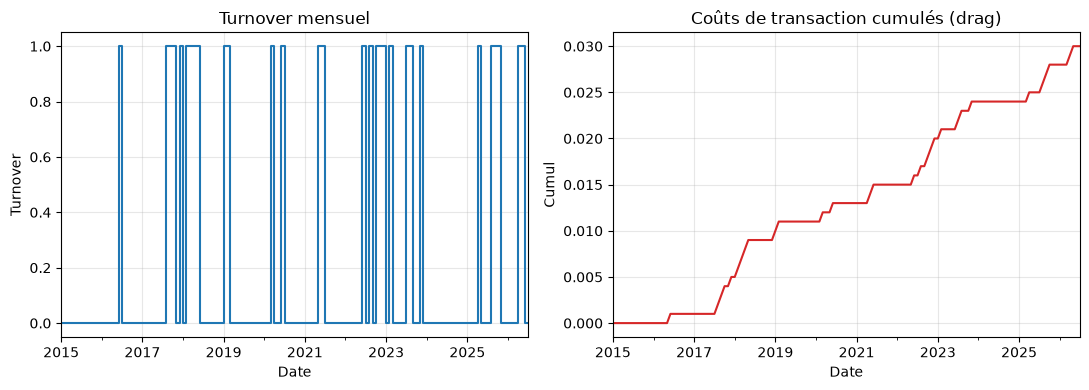

In [15]:
# 6) Turnover et 7) coûts cumulés
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
main_bt["Turnover"].plot(ax=ax1, drawstyle="steps-post")
ax1.set_title("Turnover mensuel"); ax1.set_ylabel("Turnover"); ax1.grid(True, alpha=0.3)
main_bt["Transaction Cost"].cumsum().plot(ax=ax2, color="#d62728")
ax2.set_title("Coûts de transaction cumulés (drag)"); ax2.set_ylabel("Cumul"); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 10. Contrôles finaux

In [16]:
ew = main_res["executed_weights"]
w = ew.to_numpy()

# Poids valides
assert (w >= -1e-9).all() and (w <= 1 + 1e-9).all(), "Poids hors [0, 1]."
assert np.allclose(ew.sum(axis=1), 1.0), "Les poids ne totalisent pas 1."

# Absence d'anticipation : première période en cash, exécution = cible décalée d'un mois.
assert ew.iloc[0][CASH_COLUMN] == 1.0, "La première période doit être 100% cash."
assert main_res["target_weights"].iloc[:-1].round(10).reset_index(drop=True).equals(
    ew.iloc[1:].round(10).reset_index(drop=True)), "Le décalage d'un mois n'est pas respecté."

# Drawdown <= 0, capital > 0
assert (compute_drawdown(main_equity) <= 1e-9).all(), "Drawdown positif détecté."
assert (main_equity > 0).all(), "Capital non strictement positif."

# Métriques présentes
main_summary = performance_summary(main_bt["Net Return"].dropna(), main_equity, periods_per_year=PPY)
for k in ["CAGR", "Volatility", "Sharpe", "Max Drawdown", "Best Year", "Worst Year", "Final Capital"]:
    assert k in main_summary.index, f"Métrique absente : {k}"

# Les frais réduisent (ou égalent) la performance, toutes choses égales par ailleurs.
_, bt_tc0 = run_config(universe_prices, 12, 1, 10, 1, 0.0)
_, bt_tc1 = run_config(universe_prices, 12, 1, 10, 1, 0.001)
assert bt_tc0["Equity Curve"].iloc[-1] >= bt_tc1["Equity Curve"].iloc[-1] - 1e-9, "Les frais devraient réduire la performance."

# Reproductibilité
_, bt_repeat = run_config(universe_prices, 12, 1, 10, 1, 0.001)
assert np.allclose(bt_repeat["Equity Curve"].to_numpy(), strategies["Mom 12-1 + MA10"]["Equity Curve"].to_numpy()), "Résultat non reproductible."

# Sorties finales sans NaN
assert not main_equity.isna().any() and not main_bt["Net Return"].isna().any(), "NaN dans les sorties finales."

print("Tous les contrôles passent.")

Tous les contrôles passent.


In [17]:
print("Projet 2 — Momentum défensif PEA validé techniquement.")
print("Validation technique ne signifie pas recommandation d'investissement réel.")

Projet 2 — Momentum défensif PEA validé techniquement.
Validation technique ne signifie pas recommandation d'investissement réel.
